<a href="https://colab.research.google.com/github/RebeccaDai615/3-Pano-to-4view_GSVI/blob/main/3_Pano_to_4view_GSVI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
## connect to google drive
from google.colab import drive
drive.mount('/content/drive/')
print('conecting finish')

MessageError: Error: credential propagation was unsuccessful

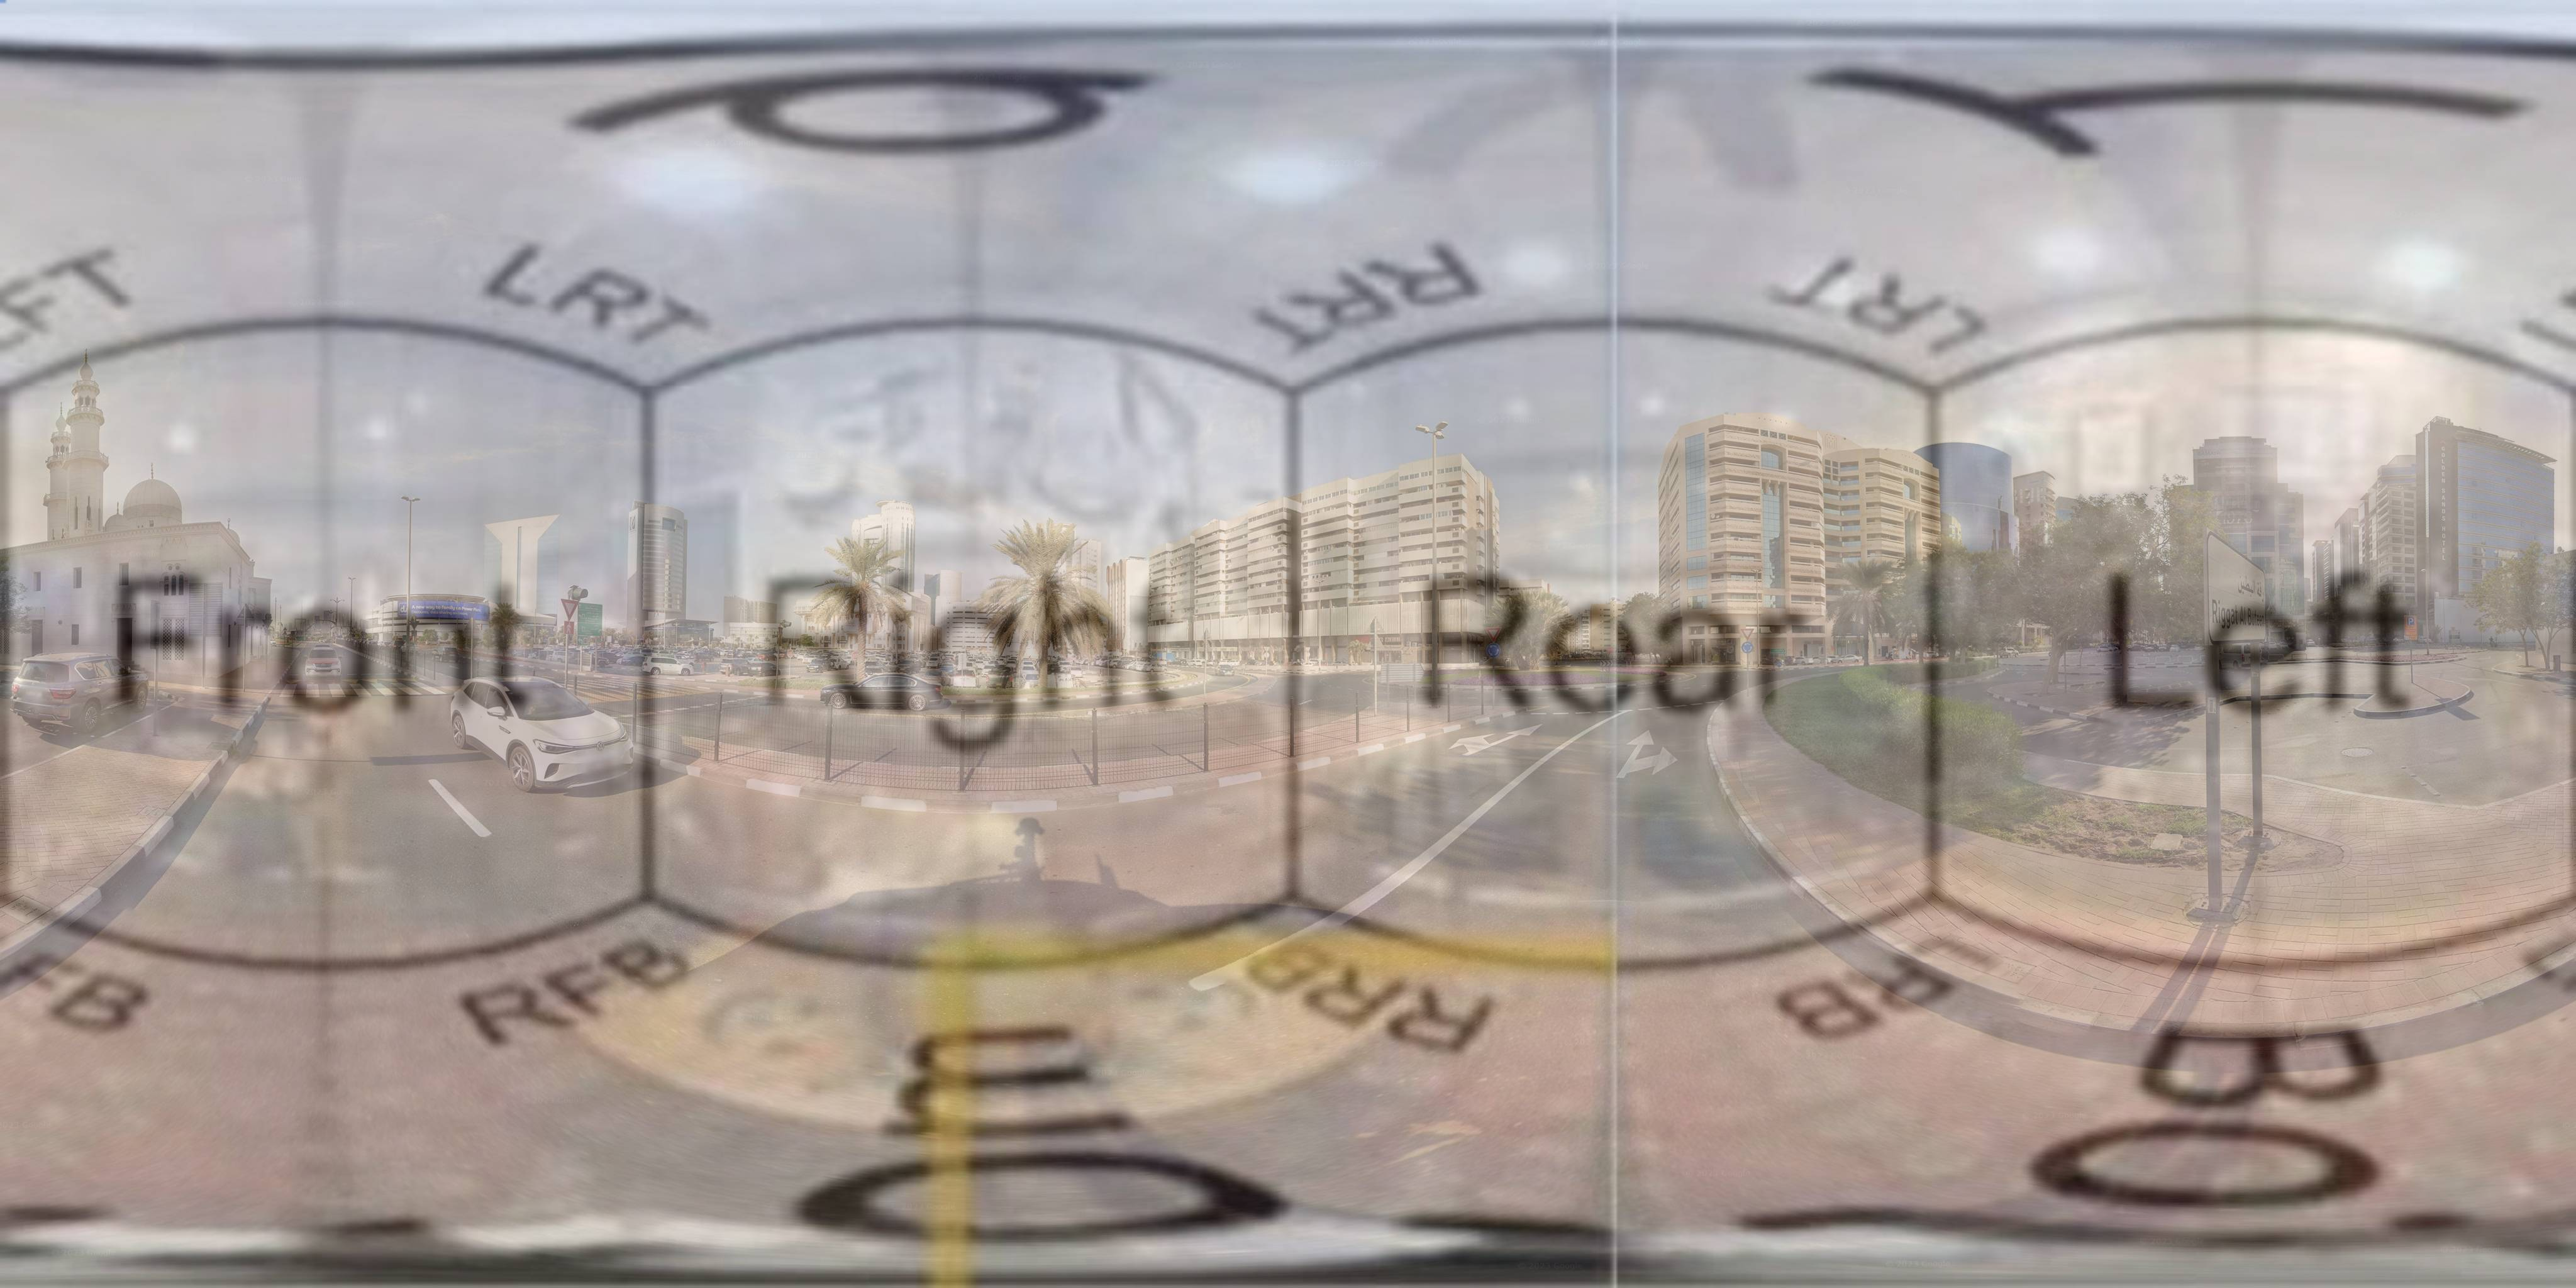

In [ ]:
import cv2
import numpy as np
import os
from pathlib import Path
import math
import shutil

# =============================================================================
# CONFIGURATION — Edit these two lines before running
# =============================================================================
BASE_DIR        = "/content/drive/MyDrive/SVI/GPan"   # Main folder
INPUT_SUBDIR    = "pano_shift72"                          # Subfolder inside BASE_DIR that contains input images
# =============================================================================
# All output folders (black-filtered + 4 directions) will be created
# automatically inside BASE_DIR.
# =============================================================================


def spherical_to_perspective(panorama, fov_h=90, fov_v=90, theta=0, phi=0, output_width=800, output_height=600):
    """
    Convert a spherical panorama to a perspective projection image.

    Parameters:
    - panorama: input panorama image
    - fov_h: horizontal field of view (degrees)
    - fov_v: vertical field of view (degrees)
    - theta: horizontal rotation angle (degrees, 0 = forward)
    - phi: vertical rotation angle (degrees, 0 = horizon)
    - output_width: output image width
    - output_height: output image height
    """

    pano_height, pano_width = panorama.shape[:2]

    x = np.linspace(-1, 1, output_width)
    y = np.linspace(-1, 1, output_height)
    x_grid, y_grid = np.meshgrid(x, y)

    f_x = 1.0 / math.tan(math.radians(fov_h) / 2.0)
    f_y = 1.0 / math.tan(math.radians(fov_v) / 2.0)

    x_3d = x_grid / f_x
    y_3d = -y_grid / f_y  # Flip Y-axis to correct vertical inversion
    z_3d = np.ones_like(x_grid)

    norm = np.sqrt(x_3d**2 + y_3d**2 + z_3d**2)
    x_3d /= norm
    y_3d /= norm
    z_3d /= norm

    theta_rad = math.radians(theta)
    phi_rad   = math.radians(phi)

    # Rotate around Y-axis (horizontal)
    x_rot = x_3d * math.cos(theta_rad) + z_3d * math.sin(theta_rad)
    y_rot = y_3d
    z_rot = -x_3d * math.sin(theta_rad) + z_3d * math.cos(theta_rad)

    # Rotate around X-axis (vertical)
    x_final = x_rot
    y_final = y_rot * math.cos(phi_rad) - z_rot * math.sin(phi_rad)
    z_final = y_rot * math.sin(phi_rad) + z_rot * math.cos(phi_rad)

    longitude = np.arctan2(x_final, z_final)
    latitude  = np.arcsin(np.clip(y_final, -1, 1))

    u = (longitude / (2 * math.pi) + 0.5) * pano_width
    v = (0.5 - latitude / math.pi) * pano_height

    u = np.clip(u, 0, pano_width - 1)
    v = np.clip(v, 0, pano_height - 1)

    map_x = u.astype(np.float32)
    map_y = v.astype(np.float32)

    result = cv2.remap(panorama, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_WRAP)
    return result


def process_panorama(input_path, output_dirs, black_output_dir, output_width=800, output_height=600):
    """
    Process a single panorama and generate four directional views.
    """
    panorama = cv2.imread(input_path)
    if panorama is None:
        print(f"  Failed to read image: {input_path}")
        return "error"

    print(f"  Original size: {panorama.shape[1]}x{panorama.shape[0]}")

    filename = Path(input_path).stem

    # Calculate ratio of black pixels (all channels == 0)
    if len(panorama.shape) == 2:
        black_mask = (panorama == 0)
    else:
        black_mask = np.all(panorama == 0, axis=2)
    black_ratio = float(black_mask.mean())
    print(f"  Black pixel ratio: {black_ratio * 100:.2f}%")

    black_threshold = 0.07
    if black_ratio > black_threshold:
        dest_path = os.path.join(black_output_dir, f"{filename}.jpg")
        try:
            shutil.copy2(input_path, dest_path)
        except Exception:
            cv2.imwrite(dest_path, panorama, [cv2.IMWRITE_JPEG_QUALITY, 95])
        print(f"  Black ratio exceeds {black_threshold*100:.0f}% — saved to black folder, skipping split.")
        return "skipped_black"

    # Four directional views (angles confirmed via testing; Front=225 deg)
    views = {
        'Front': {'theta': 225, 'phi': 0},
        'Right': {'theta': 315, 'phi': 0},
        'Rear':  {'theta': 45,  'phi': 0},
        'Left':  {'theta': 135, 'phi': 0},
    }

    for direction, params in views.items():
        print(f"  Generating {direction} view...")
        view_image = spherical_to_perspective(
            panorama,
            fov_h=110,
            fov_v=85,
            theta=params['theta'],
            phi=params['phi'],
            output_width=output_width,
            output_height=output_height
        )
        output_path = os.path.join(output_dirs[direction], f"{filename}.jpg")
        cv2.imwrite(output_path, view_image, [cv2.IMWRITE_JPEG_QUALITY, 95])
        print(f"    Saved: {output_path}")

    return "ok"


def create_output_directories(base_dir):
    """
    Create output directories for four directions and black-filtered images,
    all inside base_dir.
    """
    directions = ['Front', 'Left', 'Right', 'Rear']
    output_dirs = {}
    for direction in directions:
        dir_path = os.path.join(base_dir, f"output_{direction.lower()}")
        os.makedirs(dir_path, exist_ok=True)
        output_dirs[direction] = dir_path
        print(f"  Created: {dir_path}")

    black_dir = os.path.join(base_dir, "output_black")
    os.makedirs(black_dir, exist_ok=True)
    print(f"  Created: {black_dir}")

    return output_dirs, black_dir


def main():
    print("=== Panorama Batch Conversion Tool ===")
    print(f"Base directory  : {BASE_DIR}")
    print(f"Input subfolder : {INPUT_SUBDIR}")

    input_dir = os.path.join(BASE_DIR, INPUT_SUBDIR)

    if not os.path.exists(input_dir):
        print(f"Error: input directory '{input_dir}' does not exist.")
        return

    print("\nCreating output directories...")
    output_dirs, black_output_dir = create_output_directories(BASE_DIR)

    # Collect all jpg files (deduplicated)
    image_files = set()
    for ext in ['*.jpg', '*.jpeg', '*.JPG', '*.JPEG']:
        image_files.update(Path(input_dir).glob(ext))
    image_files = list(image_files)

    if not image_files:
        print(f"No image files found in '{input_dir}'.")
        return

    print(f"\nFound {len(image_files)} image file(s). Starting processing...\n")

    success_count       = 0
    skipped_black_count = 0
    error_count         = 0

    for i, image_file in enumerate(image_files, 1):
        print(f"[{i}/{len(image_files)}] {image_file.name}")
        status = process_panorama(str(image_file), output_dirs, black_output_dir)
        if status == "ok":
            success_count += 1
        elif status == "skipped_black":
            skipped_black_count += 1
        else:
            error_count += 1

    print(f"\n=== Done ===")
    print(f"  Processed successfully : {success_count}")
    print(f"  Filtered (black)       : {skipped_black_count}")
    print(f"  Errors                 : {error_count}")
    print(f"  Total                  : {len(image_files)}")
    print(f"\nOutput folders (all inside '{BASE_DIR}'):")
    for direction, path in output_dirs.items():
        print(f"  {direction:5s} -> {path}")
    print(f"  Black -> {black_output_dir}")


if __name__ == "__main__":
    main()